<a href="https://colab.research.google.com/github/2004sreedevip/ML-Lab-/blob/main/AML_Assignment(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


REGRESSION PERFORMANCE

Linear Regression
MSE: 2900.19
RMSE: 53.85
R2 Score: 0.4526

Ridge
MSE: 2892.01
RMSE: 53.78
R2 Score: 0.4541

Lasso
MSE: 2824.57
RMSE: 53.15
R2 Score: 0.4669

CLASSIFICATION PERFORMANCE

Decision Tree (Gini)
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1 Score: 0.9333
Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Decision Tree (Entropy)
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1 Score: 0.9333
Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Logistic Regression (Ridge)
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1 Score: 0.9333
Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Logistic Regression (Lasso)
Accuracy: 0.8667
Precision: 0.875
Recall: 0.8667
F1 Score: 0.8653
Confusion Matrix:
 [[10  0  0]
 [ 0  7  3]
 [ 0  1  9]]

KNN
Accuracy: 0.9333
Precision: 0.9444
Recall: 0.9333
F1 Score: 0.9327
Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Naive Bayes
Accuracy: 0.9667
Precision: 0.9697
Recall: 0.9667
F1

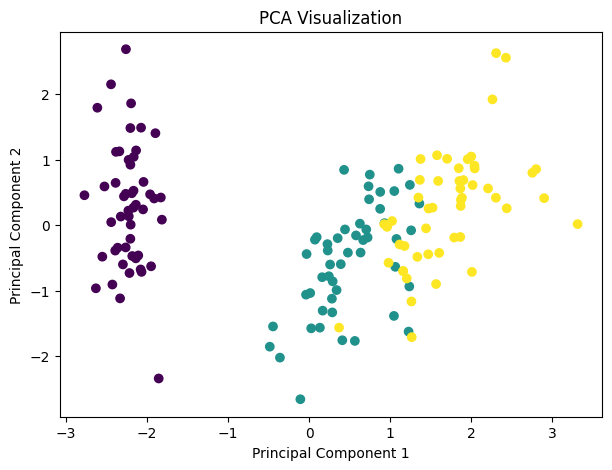

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, silhouette_score,
    davies_bouldin_score
)

data = load_diabetes()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=1.0))
}

print("\nREGRESSION PERFORMANCE")
for name, model in regression_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    print(f"\n{name}")
    print("MSE:", round(mse, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

classification_models = {
    "Decision Tree (Gini)": DecisionTreeClassifier(
        criterion="gini", random_state=42
    ),
    "Decision Tree (Entropy)": DecisionTreeClassifier(
        criterion="entropy", random_state=42
    ),
    "Logistic Regression (Ridge)": make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l2", max_iter=3000)
    ),
    "Logistic Regression (Lasso)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1", solver="liblinear", max_iter=3000
        )
    ),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=50, random_state=42
    )
}

classification_results = []

print("\nCLASSIFICATION PERFORMANCE")
for name, model in classification_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(
        y_test, pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, pred, average="weighted", zero_division=0
    )

    classification_results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4)
    })

    print(f"\n{name}")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))

print("\nClassification Comparison Table")
print(pd.DataFrame(classification_results).to_string(index=False))

X_cluster = StandardScaler().fit_transform(load_iris().data)

clustering_models = {
    "K-Means": KMeans(
        n_clusters=3, random_state=42, n_init=10
    ),
    "Hierarchical Single": AgglomerativeClustering(
        n_clusters=3, linkage="single"
    ),
    "Hierarchical Complete": AgglomerativeClustering(
        n_clusters=3, linkage="complete"
    ),
    "Hierarchical Average": AgglomerativeClustering(
        n_clusters=3, linkage="average"
    ),
    "Gaussian Mixture Model": GaussianMixture(
        n_components=3, random_state=42
    )
}

print("\nCLUSTERING PERFORMANCE")
for name, model in clustering_models.items():
    labels = model.fit_predict(X_cluster)

    sil = silhouette_score(X_cluster, labels)
    db = davies_bouldin_score(X_cluster, labels)

    print(f"\n{name}")
    print("Silhouette Score:", round(sil, 4))
    print("Davies-Bouldin Index:", round(db, 4))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

print("\nPCA PERFORMANCE")
print("Original dimensions:", X_cluster.shape[1])
print("Reduced dimensions:", X_pca.shape[1])
print("Explained variance ratio:",
      np.round(pca.explained_variance_ratio_, 4))
print("Total variance retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=load_iris().target)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")
plt.show()